# Import all packages

In [1]:
using DifferentialEquations
using OrdinaryDiffEq
using DiffEqBase
using Sundials
using ODEInterfaceDiffEq
using Plots
using Measures
using CSV
using DataFrames
# using Turing
# using MCMCChains
using EasyFit
using StatsPlots
using LinearAlgebra
using Random
using Distributions
using OrdinaryDiffEq
Random.seed!(145975);
using CmdStan
using KernelDensity
using LaTeXStrings
using StatsBase
using JLD2
using BlackBoxOptim
using BlackBoxOptim: num_func_evals
using HypothesisTests
using BayesianOptimization, GaussianProcesses

# using CairoMakie
# using PairPlots
# using DataFrames

set_cmdstan_home!("C:\\cmdstan\\cmdstan-2.30.0");

┌ Warning: Environment variable CMDSTAN_HOME not set. Use set_cmdstan_home!.
└ @ CmdStan C:\Users\dgomez\.julia\packages\CmdStan\2vwWj\src\CmdStan.jl:27


In [3]:
include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesInfs.jl")
include("D:\\David\\BayesianInferencesInVivoScripts\\ModelFunctionsAll.jl")
include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesOED.jl")

include("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\FunctionsInferenceScallable.jl")

CompRepUtil_Entro_OEDmc2 (generic function with 1 method)

# Define Priors

In [5]:
priorTheta, priotY0, sampsTh, sampsY0 = genPriorSamps(8000);
bounds, boundY0 = genThetaBounds();


In [6]:
priorInfer = hcat(sampsTh, sampsY0)

8000×17 Matrix{Float64}:
 30.612   51.23  0.00390857   0.0434508   …  20.0  386.8    3055.51  0.200992
 35.3181  51.23  0.00398123   0.00963414     20.0  838.671  2643.71  0.41913
 41.0061  51.23  0.00192012   0.0427602      20.0  501.962  3856.45  0.558348
 37.6889  51.23  0.000605313  0.0296378      20.0  699.738  5849.08  0.362255
 48.7497  51.23  0.00186232   0.00602609     20.0  667.307  2689.05  0.293185
 50.3144  51.23  0.000195509  0.0889924   …  20.0  476.238  4775.25  0.300746
 40.2798  51.23  0.00576633   0.0454737      20.0  561.174  3522.84  0.624244
 28.4925  51.23  0.00412169   0.0626817      20.0  740.584  1428.27  0.899276
 60.1832  51.23  0.00641637   0.0341233      20.0  284.044  4246.54  0.19617
 43.0183  51.23  0.000194591  0.00269883     20.0  491.932  4632.95  0.272317
  ⋮                                       ⋱                    ⋮     
 42.4355  51.23  0.00407989   0.035219       20.0  591.15   4615.72  0.53263
 19.3441  51.23  0.000662789  0.0504724      20.0 

# Compute Objective Function for All Available Experiments

In [7]:
global tsC2 = vcat(0, collect(15:5:395));
global ts = 0:tsC2[end];
global samps = convert.(Int, tsC2);

global sampsTh = priorInfer[:,1:14];
global sampsY0 = priorInfer[:,15:end];

pyrs = [0.6, 0.8, 1.6, 3.2, 6, 6.4, 8.3, 12.8, 13.1, 18, 25.6, 29, 40]

objs = zeros(length(pyrs))

for i in 1:length(pyrs)
    objs[i] = CompRepUtil_Entro_OEDmc2([pyrs[i]])
end

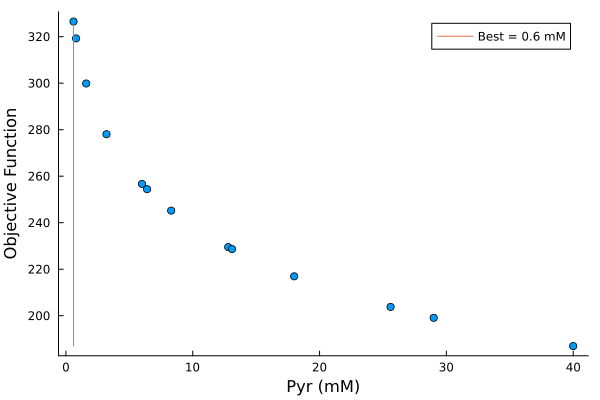

In [8]:
bstIn = findfirst(objs .== maximum(objs))

Plots.scatter(pyrs, objs, label = "", grid = false, ylabel = "Objective Function", xlabel = "Pyr (mM)")
Plots.plot!([pyrs[bstIn], pyrs[bstIn]], [minimum(objs), objs[bstIn]], label = "Best = "*string(pyrs[bstIn])*" mM")

# Extract Experimental Data

In [19]:
mainpath = "D:\\David\\BayesianInferencesInVivoScripts\\ProcessedData\\";
i = 1;
paths = [mainpath*"3Mil_"*replace(string(pyrs[bstIn]), "." => "-", count = 1)*"mMPyr_Dat.csv"];
conce = [pyrs[bstIn]];


Random.seed!(8987654);
global dat = restructDatInfCompRep_RealExpDat_Scal(paths, conce, rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], [3e6])

Dict{String, Any} with 16 entries:
  "Means"  => [1226.15; 723.012; … ; 0.320623; -12.1299;;; 0.0; 13.1925; … ; -3…
  "stsl"   => [77;;]
  "obSta"  => [1 2]
  "sts"    => [0; 20; … ; 390; 395;;]
  "obser"  => 2
  "Y0us"   => [600.0; 0.0; … ; 0.0; 1226.15;;]
  "ts"     => [1.0e-20; 1.0; … ; 394.0; 395.0;;]
  "itp"    => [0.0]
  "ScFms"  => [17.0298;;]
  "ncells" => [4;;]
  "stslm"  => 77
  "tml"    => 396
  "Erros"  => [81.2187; 72.3012; … ; 4.42203; 8.64195;;; 1.0; 1.31925; … ; 1.84…
  "m"      => 1
  "nmCls"  => [3.0e6;;]
  "nts"    => [395;;]

# Simulate Experiment Prior Prediction
CAREFUL!!! Simulations take a minute or more if you take all the samples!

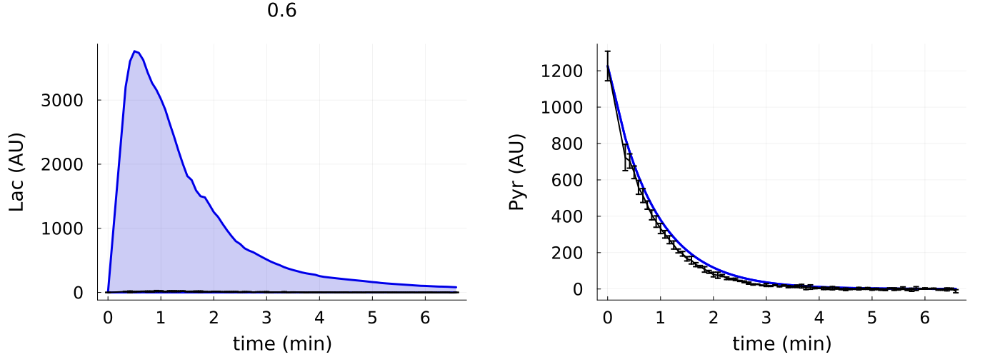

In [20]:
simPriorPredictAll(2000, dat, priorInfer[:,1:14], priorInfer[:,15:end], conce)

# MLE to obtain a good first guess for inference

In [21]:
p = [48, 51.23, 0.044, 0.02, 0.02, 0.001, 0.01, 0.0003, 0.0001, 0.0002, 1e-1, 1e-6, 3e6, 50/(15*0.12), 5000/(15*0.12), 700/(15*0.12)];
ObjectFunctMECp_Multi_MLE2(p)

3.1017698374089505e15

In [22]:
Iters = 1;
CCsT = Array{Any}(undef,Iters);
FitsT = Array{Any}(undef,Iters);

i=1
fitness_progress_history = Array{Tuple{Int, Float64},1}()
callback = oc -> push!(fitness_progress_history, (num_func_evals(oc), best_fitness(oc)))

resM = bboptimize(ObjectFunctMECp_Multi_MLE2; SearchRange = vcat([(bounds[1][i], bounds[2][i]) for i in 1:13], [(boundY0[1][i], boundY0[2][i]) for i in 1:3]), # T1_X, T1_P, kin, kpl, kf, kr, a1, a2, a3, b1, b2, b3
        MaxTime = 60*5, method = :adaptive_de_rand_1_bin, 
        CallbackFunction = callback, CallbackInterval = 0.0)

CCsT[i] = fitness_progress_history;
FitsT[i] = resM;

Starting optimization with optimizer DiffEvoOpt{FitPopulation{Float64}, RadiusLimitedSelector, BlackBoxOptim.AdaptiveDiffEvoRandBin{3}, RandomBound{ContinuousRectSearchSpace}}
0.00 secs, 0 evals, 0 steps
0.50 secs, 175 evals, 103 steps, improv/step: 0.466 (last = 0.4660), fitness=221.873434071
1.03 secs, 335 evals, 241 steps, improv/step: 0.465 (last = 0.4638), fitness=212.415430475
1.53 secs, 555 evals, 453 steps, improv/step: 0.397 (last = 0.3208), fitness=211.248550113
2.09 secs, 769 evals, 667 steps, improv/step: 0.349 (last = 0.2477), fitness=203.389578270
2.60 secs, 992 evals, 890 steps, improv/step: 0.317 (last = 0.2197), fitness=201.955564728
3.11 secs, 1216 evals, 1117 steps, improv/step: 0.283 (last = 0.1498), fitness=201.955564728
3.62 secs, 1395 evals, 1299 steps, improv/step: 0.258 (last = 0.1044), fitness=201.955564728
4.12 secs, 1620 evals, 1526 steps, improv/step: 0.244 (last = 0.1674), fitness=201.808867882
4.66 secs, 1821 evals, 1730 steps, improv/step: 0.224 (last = 

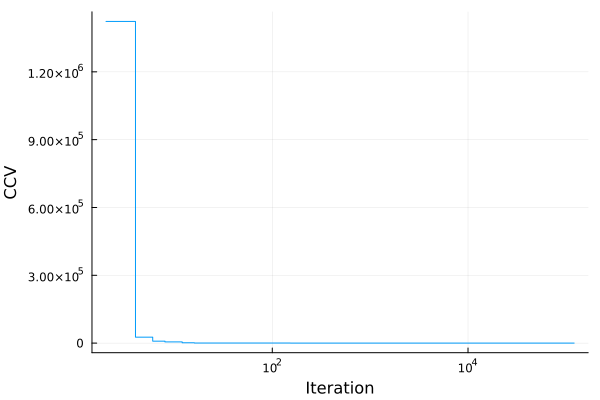

┌ Warning: Attempting to store var"#107#108".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447
┌ Warning: Attempting to store BlackBoxOptim.var"#114#115".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447


In [25]:
# Plot convergence curve
pl=plot(CCsT[1], xaxis=:log, linetype=:step, label = "", xlabel = "Iteration", ylabel = "CCV")
display(pl)

# Extract Parameter Vector
parfitT = zeros(16, Iters);
for i in 1:Iters
    parfitT[:,i] = best_candidate(FitsT[i]);
end
bestPind = findfirst([CCsT[i][end][2] for i in 1:length(CCsT)] .== minimum([CCsT[i][end][2] for i in 1:length(CCsT)]))
ppT = parfitT[:,bestPind];

# Save Data
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\MLEResults\\resMTRRCmp_Exper_Iter1.jld2", "FitsT",FitsT)
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\MLEResults\\resMVectTRRCmp_Exper_Iter1.jld2", 
        "resMMat",parfitT, "CCsT", CCsT)

In [26]:
# Load Data
ppT = JLD2.load("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\MLEResults\\resMVectTRRCmp_Exper_Iter1.jld2")["resMMat"][:,1]

16-element Vector{Float64}:
   51.84949542216457
   51.23
    0.012499620271444014
    0.019310861705946925
    7.413300927124975e-7
    0.29965082628595685
    1.999796135147189
    0.00011394356884445628
    0.03106102844978615
    9.99997792238877e-6
    1.7166078880229754
    0.004499897229462877
    3.0e6
  181.09463649425032
 8217.501106323689
    0.17610016654238816

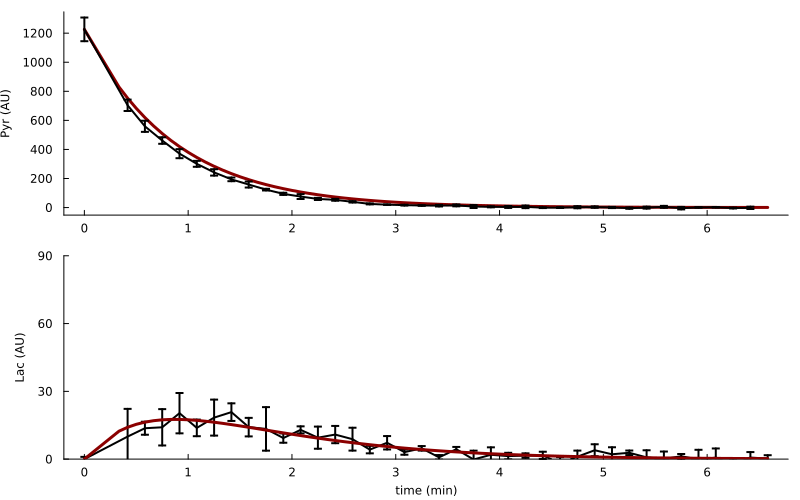

In [28]:
pst = Array{Any}(undef, length(conce))
i = 1
for i in 1:length(conce)
     tsC2 = dat["sts"][:,i];
     if i == 3
          tsC2 = dat["sts"][1:end-1,3];
     end
     ts = 0:tsC2[end];
     ivss = [round(conce[i], digits = 1)*1000, 0, 0, ppT[14], ppT[15], ppT[16], 0, 0, 0, 0, 0, round(conce[i], digits = 1)*1000, 0, round(conce[i], digits = 1)*1000*(dat["ScFms"][i]*0.12)];;
     samps = convert.(Int, tsC2);

     SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp_Scall(ts, vcat(ppT[1:13], dat["ScFms"][i], 0), ivss, samps);

     pps = plot(dat["sts"][1:2:end,i]./60, dat["Means"][1:2:end,i,2], yerror = dat["Erros"][1:2:end,i,2], linewidth = 2, colour = "black", label = "",
               margin=1Plots.mm,xtickfont=font(8), ytickfont=font(8), guidefont=font(8), titlefont=font(18),
               xlabel = "time (min)", ylabel = "Lac (AU)", size = (800,500))

          plot!(tsC2./60, SimulsAll[:,13,1], linewidth=3, colour="red4", label = "", grid = false, ylim=(0,90))


     ps = plot(tsC2./60, SimulsAll[:,14,1], linewidth=3, colour="red4", label = "", grid = false,
          margin=1Plots.mm,xtickfont=font(8), ytickfont=font(8), guidefont=font(8), titlefont=font(18))
     plot!(dat["sts"][1:2:end-1,i]./60, dat["Means"][1:2:end-1,i,1], yerror = dat["Erros"][1:2:end-1,i,1], linewidth = 2, colour = "black", label = "", ylabel = "Pyr (AU)")

     pst[i] = plot(ps, pps, layout=(2,1))
end

plot(pst...)

## Compute structure for Stan's initial guess

In [30]:
jj = vcat(1, 3:12)

preTrans = zeros(14);

for i in 1:length(jj)
    
    if i == 1
        preTrans[i] = (ppT[jj[i]]-priorTheta[jj[i]].μ)/priorTheta[jj[i]].σ;
    else
        preTrans[i] = (ppT[jj[i]]-priorTheta[jj[i]].untruncated.μ)/priorTheta[jj[i]].untruncated.σ;
    end
    
end
kk = [14,15,16]
for i in 1:length(priotY0)
    preTrans[i+11] = (ppT[kk[i]]-priotY0[i].untruncated.μ)/priotY0[i].untruncated.σ;
end


samps = hcat(preTrans,preTrans,preTrans,preTrans);
names = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];

ini = genStanInitDict2(repeat(preTrans, 1, 10), names)

ini[1]

Dict{String, Any} with 14 entries:
  "kbnE" => 2.33333
  "LDH"  => -1.13264
  "kin"  => 3.99985
  "ki"   => 0.806956
  "kunE" => -0.68939
  "kpl"  => -0.297787
  "NADH" => -1.15927
  "kup"  => -0.99988
  "T1_X" => 1.09295
  "kbp"  => 1.10505
  "kr"   => 3.99989
  "NAD"  => 3.99331
  "kun"  => 0.997672
  "kbn"  => 0.48266

# Inference

In [32]:
modelpath = "D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\HP_PyrLac_CmpRepresMo_Scallable2.stan";
stream = open(modelpath,"r");
Model = read(stream,String);
close(stream);

StanModel = Stanmodel(name="PyrCompRepr_Iter1_Try1", model=Model, nchains =10,
            num_samples  = 800, num_warmup = 200, printsummary=true);
StanModel.method.save_warmup = true;
StanModel.method.adapt.delta = 0.9;
StanModel.method.algorithm.stepsize = 0.1;
StanModel.method.algorithm.engine.max_depth=11;
# StanModel.method.algorithm.stepsize_jitter = 0.5;

# StanModel = Stanmodel(name="PyrCompRepr_Iter2_Try1", model=Model, nchains =10,
#             num_samples  = 800, num_warmup = 400, printsummary=true);
# StanModel.method.save_warmup = true;
# StanModel.method.adapt.delta = 0.90;
# StanModel.method.algorithm.stepsize = 0.1;
# StanModel.method.algorithm.engine.max_depth=10;
# StanModel.method.algorithm.stepsize_jitter = 0.5;

11

In [33]:
rc, chns, cnames = stan(StanModel, dat, init = ini) 


Inference for Stan model: PyrCompRepr_Iter1_Try1_model
10 chains: each with iter=(800,800,800,800,800,800,800,800,800,800); warmup=(200,200,200,200,200,200,200,200,200,200); thin=(1,1,1,1,1,1,1,1,1,1); 10000 iterations saved.

Warmup took (3755, 3298, 3869, 2939, 2944, 3147, 3064, 2843, 4368, 3138) seconds, 9.3 hours total
Sampling took (17292, 10687, 13745, 11393, 9121, 9574, 9244, 10370, 12857, 11800) seconds, 32 hours total

                    Mean     MCSE   StdDev        5%       50%       95%    N_Eff  N_Eff/s    R_hat

lp__            -1.8e+02  6.9e-02  3.1e+00  -1.9e+02  -1.8e+02  -1.8e+02  2.1e+03  1.8e-02  1.0e+00
accept_stat__    9.6e-01  3.1e-03  6.6e-02      0.83      0.98      1.00  4.5e+02  3.9e-03  1.0e+00
stepsize__       2.3e-02  1.5e-03  3.3e-03     0.016     0.025     0.026  5.0e+00  4.3e-05  4.3e+13
treedepth__      7.3e+00  1.2e-01  5.4e-01       7.0       7.0       8.0  2.0e+01  1.7e-04  1.2e+00
n_leapfrog__     2.0e+02  1.9e+01  8.8e+01       127       255     

(0, [-221.712 0.304181 … 6659.18 0.162527; -221.712 0.0 … 6659.18 0.162527; … ; -182.06 0.999989 … 1990.66 0.161143; -184.216 0.996365 … 5653.19 0.141228;;; -227.978 0.00402785 … 8217.5 0.17576; -227.978 5.61338e-51 … 8217.5 0.17576; … ; -180.895 0.996044 … 2159.65 0.292548; -183.554 0.935603 … 6728.41 0.029155;;; -215.51 0.389553 … 5887.79 0.169963; -215.51 0.0 … 5887.79 0.169963; … ; -180.561 0.939412 … 5760.6 0.109845; -180.186 0.998563 … 3109.99 0.18639;;; -207.47 0.950103 … 1887.67 0.111838; -207.47 0.0 … 1887.67 0.111838; … ; -182.265 0.807615 … 2867.7 0.188274; -183.261 0.997696 … 4719.44 0.35912;;; -210.515 0.180638 … 2309.08 0.147428; -210.515 4.3243e-215 … 2309.08 0.147428; … ; -182.418 0.999486 … 2171.27 0.317872; -182.538 0.981849 … 2374.46 0.319865;;; -220.524 0.285918 … 7280.12 0.162443; -220.524 0.0 … 7280.12 0.162443; … ; -183.064 0.997153 … 2908.34 0.028772; -182.089 0.907523 … 1997.13 0.132121;;; -227.978 0.00206704 … 8217.5 0.17576; -227.978 0.000255649 … 8217.5 0.17

In [36]:
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PyrCompetitiveRepressionInferExpScal_Iter1_Try1.jld", "rc", rc, "chns", chns, "cnames", cnames)

poster = vcat(chns[201:end, end-16:end, 1], chns[201:end, end-16:end, 2], chns[201:end, end-16:end, 3], chns[201:end, end-16:end, 4], chns[201:end, end-16:end, 5], 
              chns[201:end, end-16:end, 6], chns[201:end, end-16:end, 7], chns[201:end, end-16:end, 8], chns[201:end, end-16:end, 9], chns[201:end, end-16:end, 10])
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter1_Try1.jld", "poster", poster)
CSV.write("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter1_Try1.csv", DataFrame(poster, :auto))

"D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter1_Try1.csv"

In [37]:
poster = Matrix(CSV.read("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter1_Try1.csv", DataFrame))

8000×17 Matrix{Float64}:
 47.3787  51.23  0.00155966  0.0145029  …  531.554   1924.36   0.0859339
 43.4375  51.23  0.00104747  0.0147182     262.31     711.768  0.0681909
 39.4956  51.23  0.00578949  0.0152421     493.286    417.298  0.196644
 46.7641  51.23  0.00241599  0.0178411     196.229   4292.87   0.181209
 37.6573  51.23  0.00487215  0.0137971     604.984   4035.78   0.180783
 38.3438  51.23  0.00379106  0.0136018  …  579.193   4265.48   0.758058
 48.3472  51.23  0.00170405  0.0178613     415.719   3403.71   0.248787
 29.9887  51.23  0.00677593  0.0120929     509.082   3611.95   0.646214
 28.2813  51.23  0.00594078  0.0121592      71.7865  1608.42   0.480568
 51.2978  51.23  0.00362439  0.0182823     307.527   1326.18   0.0558947
  ⋮                                     ⋱               ⋮      
 35.4757  51.23  0.00365653  0.0139167     180.175   3378.62   0.252308
 32.4388  51.23  0.00422033  0.012934      209.035   3118.73   0.458853
 32.5585  51.23  0.00332311  0.0130423     2

# Plot Posterior VS Prior

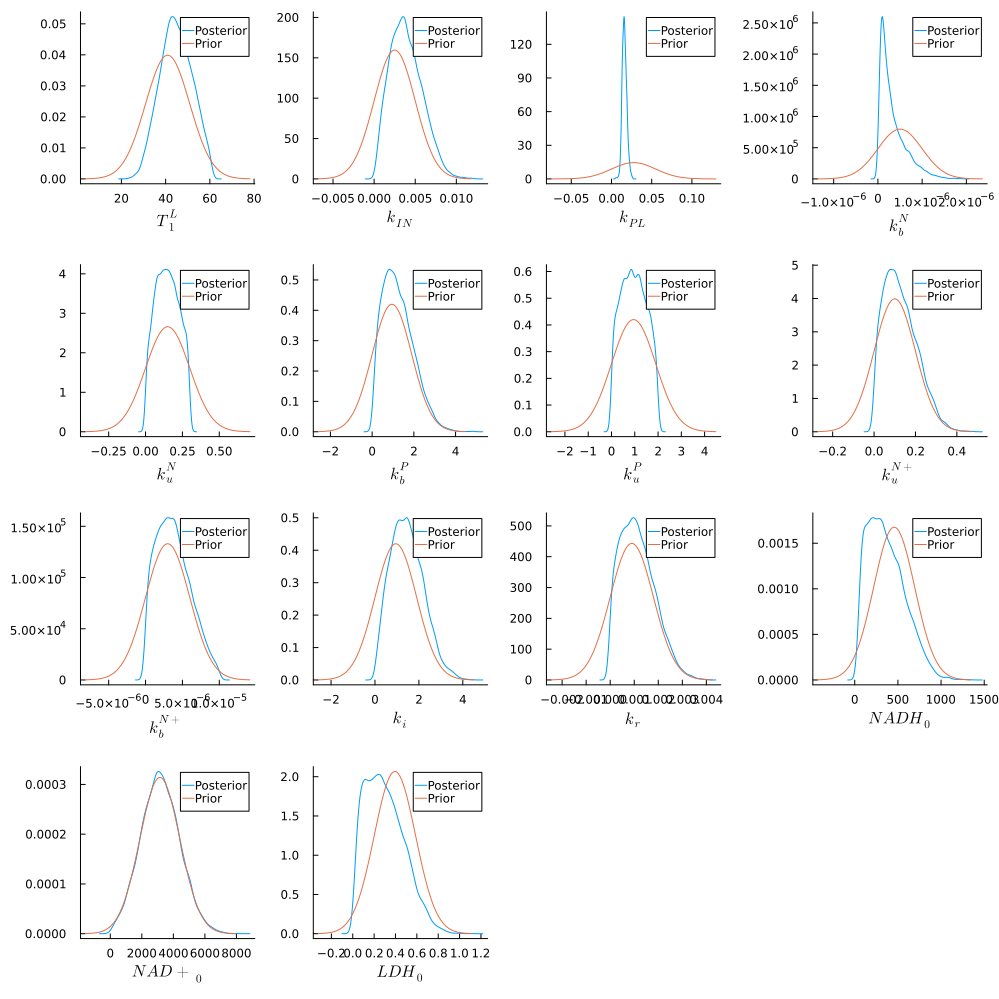

In [38]:
# namess = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];
namess = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_r",L"NADH_0",L"NAD+_0",L"LDH_0"];

indss=vcat(1, 3:12, 15:17)
prisDis = vcat(priorTheta, priotY0)

pltsPost = Array{Any}(undef, length(indss))

for i in 1:length(indss)

    pltsPost[i] = plot(kde(poster[:,indss[i]]), label = "Posterior", xlabel = namess[i])
    try
        plot!(prisDis[indss[i]].untruncated, label = "Prior")
    catch
        plot!(prisDis[indss[i]], label = "Prior")
    end

end

plot(pltsPost..., size=(1000,1000), grid = false)

In [39]:
-log(det(cov(hcat(poster[:,1], poster[:,3:12], poster[:,15:end]))))

83.83142676982585

In [40]:
[mode(poster[poster[:,11] .> 2, i]) for i in 1:17]

17-element Vector{Float64}:
   55.8178
   51.23
    0.00586843
    0.0181284
    5.3643e-7
    0.279366
    1.0126
    1.47283
    0.0861807
    3.84557e-6
    2.50842
    0.00131699
    3.0e6
   17.0298
  108.485
 4263.67
    0.200483

In [42]:
using CairoMakie
using PairPlots
using DataFrames

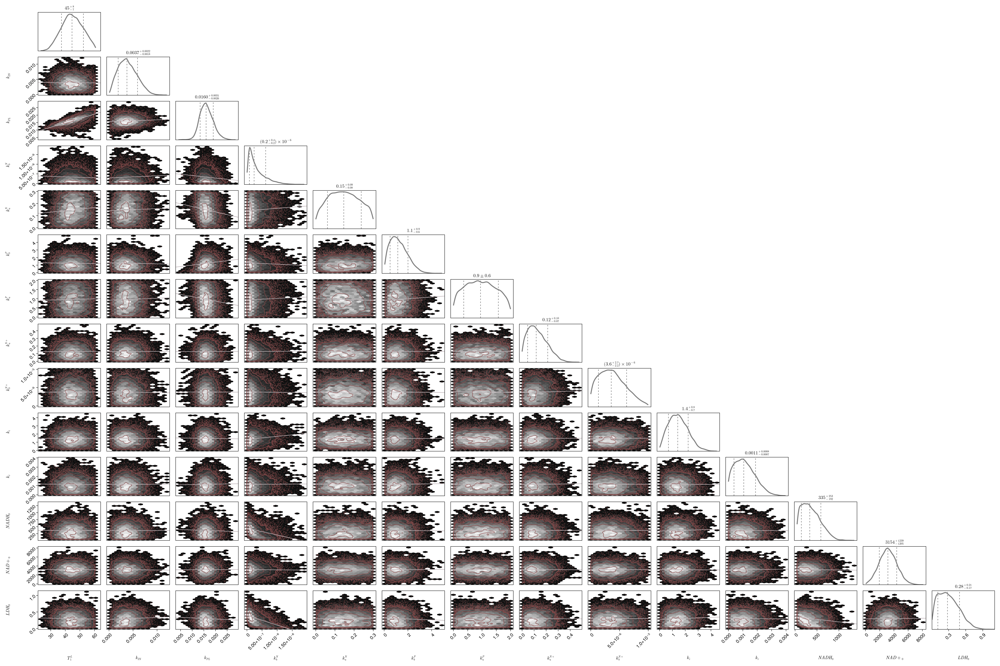

In [43]:
label = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_r",L"NADH_0",L"NAD+_0",L"LDH_0"]

postCut = hcat(poster[:,1], poster[:,3:12], poster[:,15:end]);
df = DataFrame(postCut, :auto)

fig = Figure(size=(3000,2000))
# 
pairplot(fig[1,1], df => (
    PairPlots.HexBin(colormap=:grays, alpha=1), # RdYlGn
    PairPlots.Scatter(filtersigma=2, color="#884a4aff", markersize=3, alpha=0.65),
    PairPlots.Contour(color="#884a4aff", alpha=0.85),
    # # New:
    
    PairPlots.MarginConfidenceLimits(),
    PairPlots.MarginDensity(color="gray", linewidth=3),
    PairPlots.TrendLine(color="#c0b5b9ff"), # default is red
    
), 
labels = Dict(:x1 => label[1],:x2 => label[2],:x3 => label[3],:x4 => label[4],:x5 => label[5],:x6 => label[6],:x7 => label[7],:x8 => label[8],:x9 => label[9],:x10 => label[10],
              :x11 => label[11],:x12 => label[12],:x13 => label[13],:x14 => label[14]))

# save("D:\\David\\BayesianInferencesInVivoScripts\\Figures\\SuppFig6Stuff\\PosteriorCovariance_InitialExperiment.svg", fig)


fig

# Simulate Experiment Current Posterior

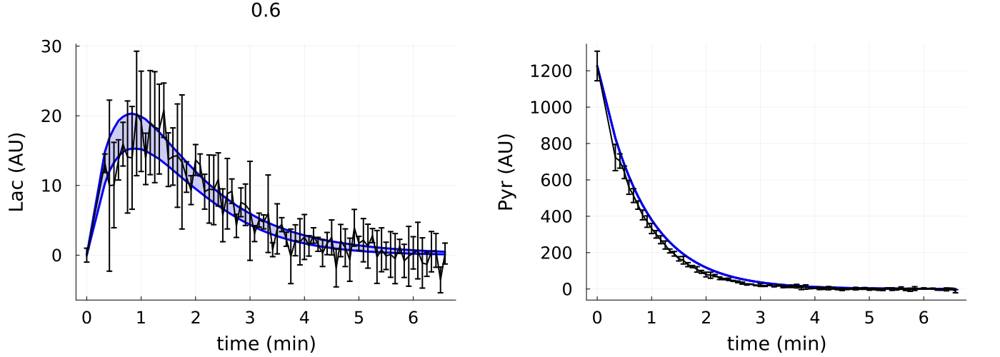

In [45]:
simPriorPredictAll(2000, dat, poster[:,1:14], poster[:,15:end], conce)

In [46]:
dat

Dict{String, Any} with 16 entries:
  "Means"  => [1226.15; 723.012; … ; 0.320623; -12.1299;;; 0.0; 13.1925; … ; -3…
  "stsl"   => [77;;]
  "obSta"  => [1 2]
  "sts"    => [0; 20; … ; 390; 395;;]
  "obser"  => 2
  "Y0us"   => [600.0; 0.0; … ; 0.0; 1226.15;;]
  "ts"     => [1.0e-20; 1.0; … ; 394.0; 395.0;;]
  "itp"    => [0.0]
  "ScFms"  => [17.0298;;]
  "ncells" => [4;;]
  "stslm"  => 77
  "tml"    => 396
  "Erros"  => [81.2187; 72.3012; … ; 4.42203; 8.64195;;; 1.0; 1.31925; … ; 1.84…
  "m"      => 1
  "nmCls"  => [3.0e6;;]
  "nts"    => [395;;]